# 05. AI-generated images and how exploitable the fire head is
Results from `docs/data/authenticity_synthetic.json` (`scripts/gen_synthetic.py`, `build_synth_set.py`, `build_control_set.py`, `eval_synthetic.py`). Generators with licences read from their model cards: **SD 1.5 and SDXL are used for training; PixArt-alpha and Kolors are held out entirely**.

**Read the caveat first:** these are four open diffusion models with simple prompts at 512 px / JPEG q90, so near-perfect scores are the easy case and must not be quoted as 'AI images are detected'.

In [1]:
import json, os, sys, pathlib
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = pathlib.Path(os.getcwd()).resolve().parent if pathlib.Path(os.getcwd()).name == "notebooks" else pathlib.Path(os.getcwd())
sys.path.insert(0, str(ROOT / "src"))
J = lambda n: json.load(open(ROOT / "docs" / "data" / n))
COL = {"blue": "#2f6fb3", "orange": "#d9822b", "grey": "#8a8f98", "green": "#3a9a6e", "red": "#c24d4d"}

## Detection across generator families, and under degradation
The operating threshold gives 5% false flags on real validation/calibration images.

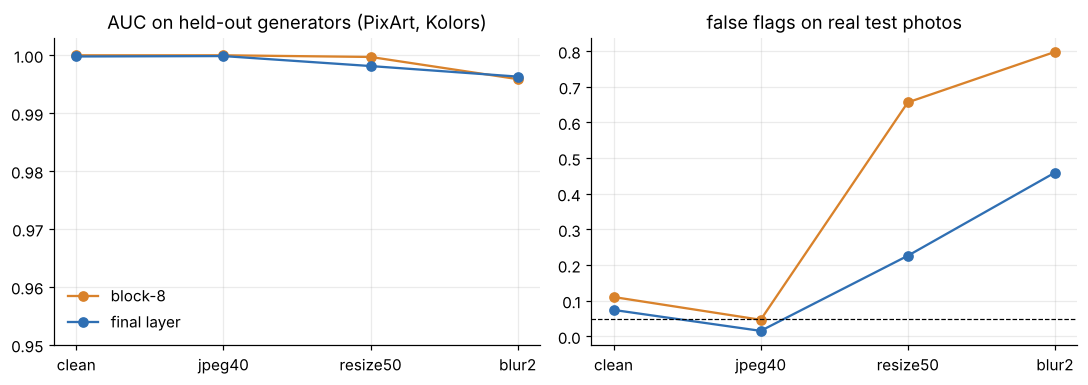

In [2]:
s = J("authenticity_synthetic.json"); conds = ["clean", "jpeg40", "resize50", "blur2"]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for key, nm, c in (("block8_cls", "block-8", COL["orange"]), ("final_embedding", "final layer", COL["blue"])):
    held = [s[key][d]["held-out generators (pixart+kolors)"] for d in conds]
    axs[0].plot(conds, [h["auc"] for h in held], "o-", color=c, label=nm); axs[1].plot(conds, [h["false_flag_real"] for h in held], "o-", color=c, label=nm)
axs[0].set_title("AUC on held-out generators (PixArt, Kolors)"); axs[0].set_ylim(.95, 1.003); axs[1].set_title("false flags on real test photos"); axs[1].axhline(.05, color="k", ls="--", lw=.8)
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()

Detection stays near-perfect, but false flags on real photos rise sharply after blur and downsizing, especially for block-8 features.

## Control: real photos from sources never seen in training
If the head merely rejected 'anything not D-Fire', these would be flagged.

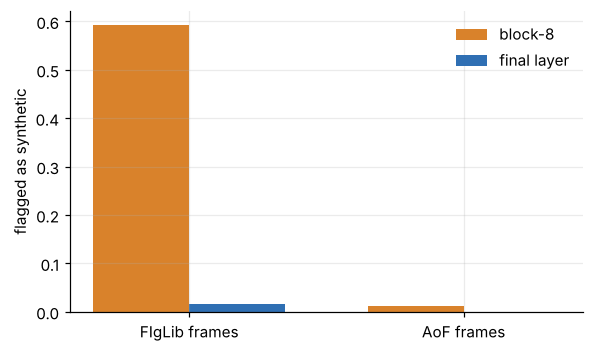

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.3)); w = .35
for i, (key, nm, c) in enumerate((("block8_cls", "block-8", COL["orange"]), ("final_embedding", "final layer", COL["blue"]))):
    ctl = s[key]["control_real_other_sources_false_flag"]; ax.bar(np.arange(2) + (i - .5) * w, [ctl["figlib"], ctl["aof"]], w, color=c, label=nm)
ax.set_xticks(range(2), ["FIgLib frames", "AoF frames"]); ax.set_ylabel("flagged as synthetic"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

The final-layer head passes this control; the block-8 head does not (59% of FIgLib frames flagged), so block-8 is unstable under source shift.

## The fire head cannot tell generated fire from real fire
A linear probe trained on real D-Fire, applied to the generated images (threshold at 5% false positives on real negatives).

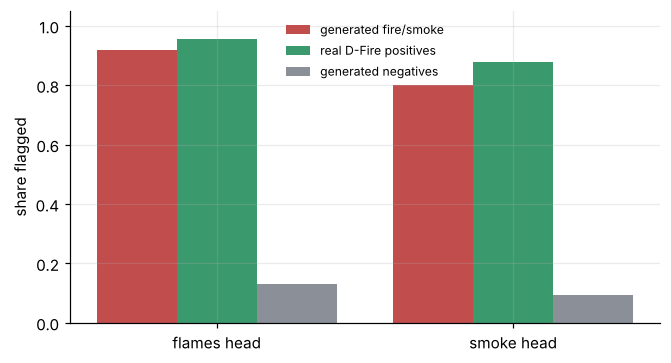

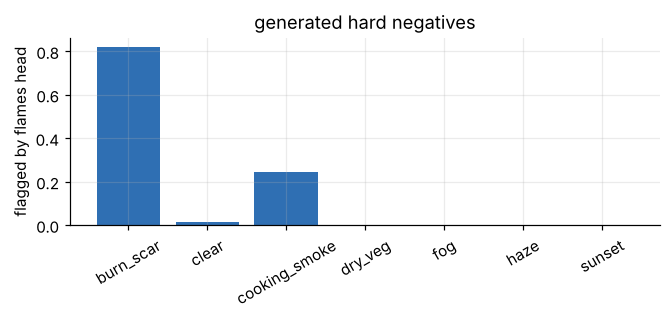

In [4]:
e = s["fire_head_on_generated_images"]; fig, ax = plt.subplots(figsize=(6.2, 3.4)); w = .27
for i, (lab, key, c) in enumerate((("generated fire/smoke", "generated_positive_flagged", COL["red"]), ("real D-Fire positives", "real_dfire_test_positive_flagged", COL["green"]), ("generated negatives", "generated_negative_flagged", COL["grey"]))):
    ax.bar(np.arange(2) + (i - 1) * w, [e["flames"][key], e["smoke"][key]], w, color=c, label=lab)
ax.set_xticks(range(2), ["flames head", "smoke head"]); ax.set_ylabel("share flagged"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()
tags = e["flames"]["flagged_by_hard_negative_tag"]; fig, ax = plt.subplots(figsize=(6.2, 3)); ax.bar(list(tags), list(tags.values()), color=COL["blue"]); ax.set_ylabel("flagged by flames head"); ax.tick_params(axis="x", rotation=30); ax.set_title("generated hard negatives"); plt.tight_layout(); plt.show()

**Why this matters:** a generated flame image scores as high as a real one, which is exactly why the design says the fire score must never be shown without the authenticity status. Generated burn scars, a labelled hard negative, are flagged as flames most of the time.